### 1. Titanic — Machine Learning from Disaster

In [704]:
import numpy as np 

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split , cross_validate, StratifiedKFold , RandomizedSearchCV , learning_curve

from sklearn.pipeline import make_pipeline

from sklearn.feature_selection import SelectKBest , f_regression

from sklearn.compose import make_column_transformer

from sklearn.preprocessing import OneHotEncoder , StandardScaler 

from sklearn.linear_model import LogisticRegression

from sklearn.neighbors import KNeighborsClassifier

from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier

from sklearn.svm import SVC

from sklearn.ensemble import VotingClassifier

from sklearn.metrics import accuracy_score

### Importation des données 

In [705]:
df_train  =  pd.read_csv("dataset/1/train.csv")

df_test  =  pd.read_csv("dataset/1/test.csv")

### Suspression des doublons

In [706]:
df_train = df_train.drop_duplicates()

In [707]:
df_train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


### Creation de X et Y et suspression des var unitile

In [708]:
X = df_train.drop(columns=["PassengerId","Survived"])

y = df_train["Survived"]

In [709]:
X

,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...
886,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [710]:
y

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64

In [711]:
X.isna().sum()

Pclass        0
Name          0
Sex           0
Age         177
SibSp         0
Parch         0
Ticket        0
Fare          0
Cabin       687
Embarked      2
dtype: int64

### Valeur unique par feature

In [712]:
X.nunique()

Pclass        3
Name        891
Sex           2
Age          88
SibSp         7
Parch         7
Ticket      681
Fare        248
Cabin       147
Embarked      3
dtype: int64

### Feature engenering  pour les variables categorielle a plus de  categorie

In [713]:
def feature_engineering(df):

    X = df.copy()

    X["Ticket_Prefix"] = (

        X["Ticket"]

        .str.replace(r"[./]", "", regex=True)

        .str.extract(r"([A-Za-z]+)", expand=False)

        .str.upper()

        .fillna("NONE")
    )

    X["Ticket_Length"] = X["Ticket"].str.len()

    X["Cabin_Deck"] = X["Cabin"].str[0].fillna("Unknown")

    X["Title"] = X["Name"].str.extract(

        r",\s*([^.]*)\.",

        expand=False

    ).str.strip()

    rare_titles = [
        "Lady", "Countess", "Capt", "Col", "Don",
        "Dr", "Major", "Rev", "Sir", "Jonkheer",
        "Dona"
    ]

    X["Title"] = X["Title"].replace(

        rare_titles,

        "Rare"
    )

    X["Family_Size"] = X["SibSp"] + X["Parch"] + 1

    X["Is_Alone"] = (

        X["Family_Size"] == 1

    ).astype(int)

    X["Fare_Per_Person"] = (

        X["Fare"] / X["Family_Size"]
    )

    X["Age_Group"] = pd.cut(

        X["Age"],

        bins=[-np.inf, 12, 18, 35, 60, np.inf],

        labels=[

            "Child",

            "Teenager",

            "Young_Adult",

            "Adult",

            "Senior"
        ]
    )

   
    X = X.drop(

        columns=["Ticket", "Cabin", "Name"]
    )

    return X




In [714]:
X = df_train.drop(columns=["Survived", "PassengerId"])

df_test = df_test.drop(columns=["PassengerId"])

X = feature_engineering(X)

In [715]:
X

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Ticket_Prefix,Ticket_Length,Cabin_Deck,Title,Family_Size,Is_Alone,Fare_Per_Person,Age_Group
0,3,male,22.0,1,0,7.2500,S,A,9,Unknown,Mr,2,0,3.62500,Young_Adult
1,1,female,38.0,1,0,71.2833,C,PC,8,C,Mrs,2,0,35.64165,Adult
2,3,female,26.0,0,0,7.9250,S,STONO,16,Unknown,Miss,1,1,7.92500,Young_Adult
3,1,female,35.0,1,0,53.1000,S,NONE,6,C,Mrs,2,0,26.55000,Young_Adult
4,3,male,35.0,0,0,8.0500,S,NONE,6,Unknown,Mr,1,1,8.05000,Young_Adult
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,2,male,27.0,0,0,13.0000,S,NONE,6,Unknown,Rare,1,1,13.00000,Young_Adult
887,1,female,19.0,0,0,30.0000,S,NONE,6,B,Miss,1,1,30.00000,Young_Adult
888,3,female,NaN,1,2,23.4500,S,WC,10,Unknown,Miss,4,0,5.86250,NaN
889,1,male,26.0,0,0,30.0000,C,NONE,6,C,Mr,1,1,30.00000,Young_Adult


### Imputation des donneés 

In [716]:
num_imputer = SimpleImputer(strategy="median")

cat_imputer  =  SimpleImputer(strategy="most_frequent")

X["Age"] = num_imputer.fit_transform(X[["Age"]])

X["Embarked"] = cat_imputer.fit_transform(X[["Embarked"]]).ravel()

X["Age_Group"] = cat_imputer.fit_transform(X[["Age_Group"]]).ravel()



### Verification des valeur manquantes

In [717]:
X.isna().sum()

Pclass             0
Sex                0
Age                0
SibSp              0
Parch              0
Fare               0
Embarked           0
Ticket_Prefix      0
Ticket_Length      0
Cabin_Deck         0
Title              0
Family_Size        0
Is_Alone           0
Fare_Per_Person    0
Age_Group          0
dtype: int64

### Visualisation des relation entre les variables et le resultat

Les variable continu


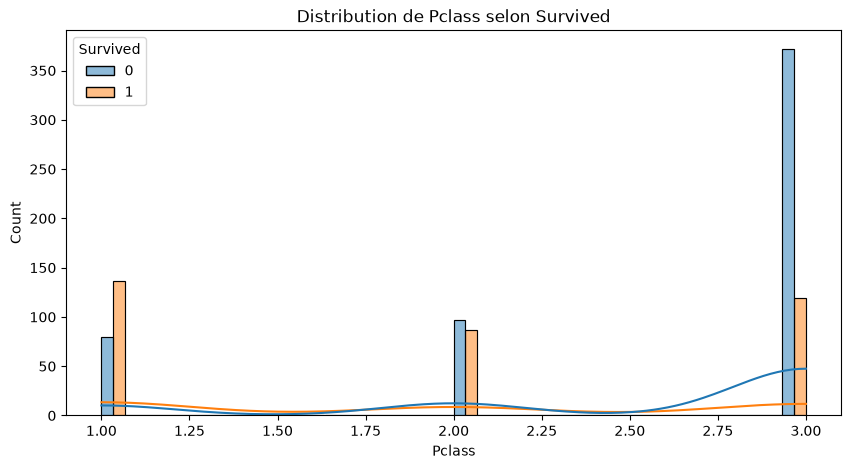

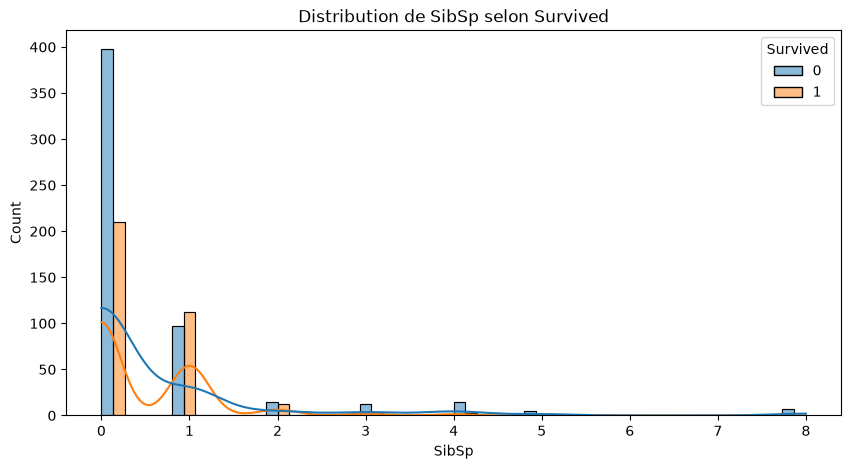

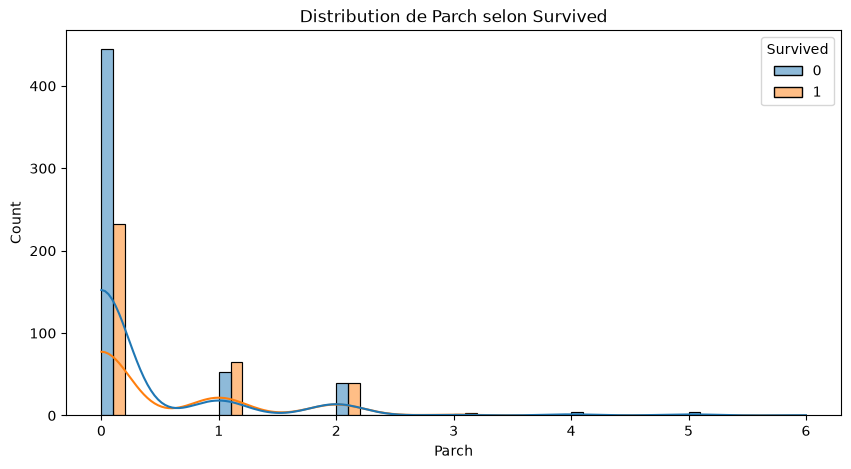

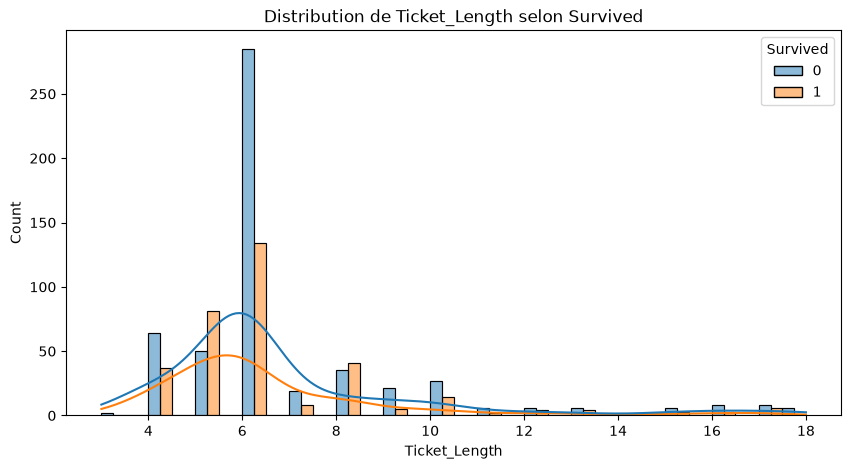

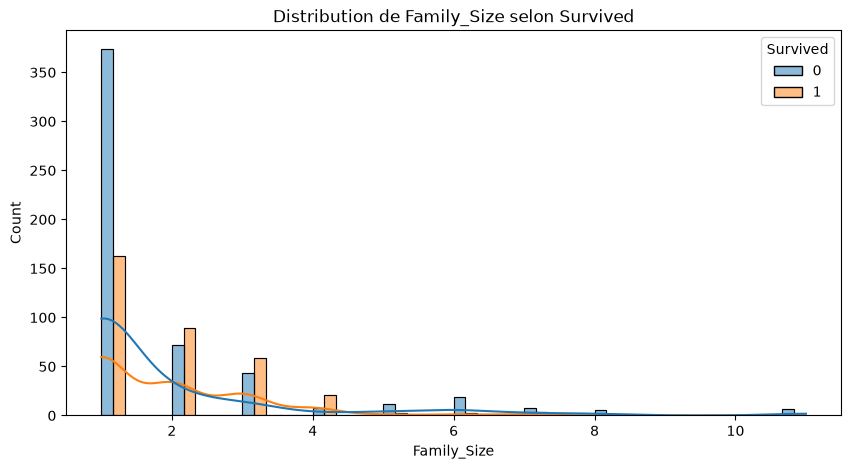

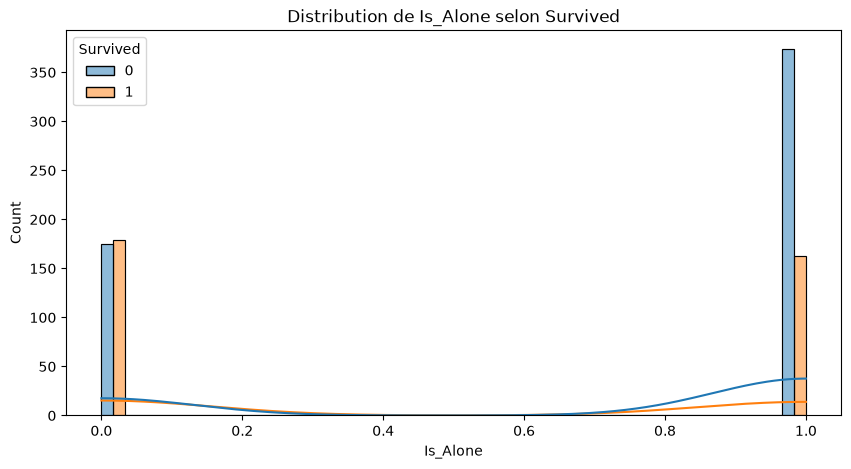

In [718]:
for col in X.select_dtypes(include="int"):

    plt.figure(figsize=(10, 5))

    sns.histplot(

        data=X,

        x=col,

        hue=y,

        bins=30,

        kde=True,

        multiple="dodge"
    )

    plt.title(f"Distribution de {col} selon Survived")


### Les variables discrète

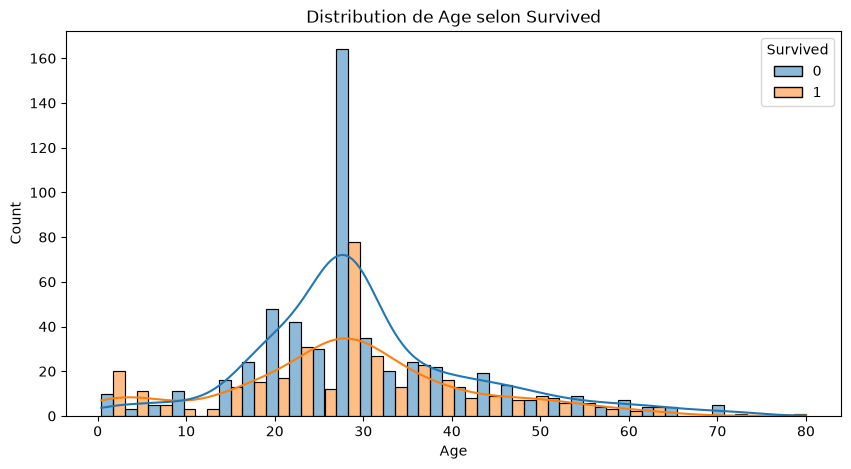

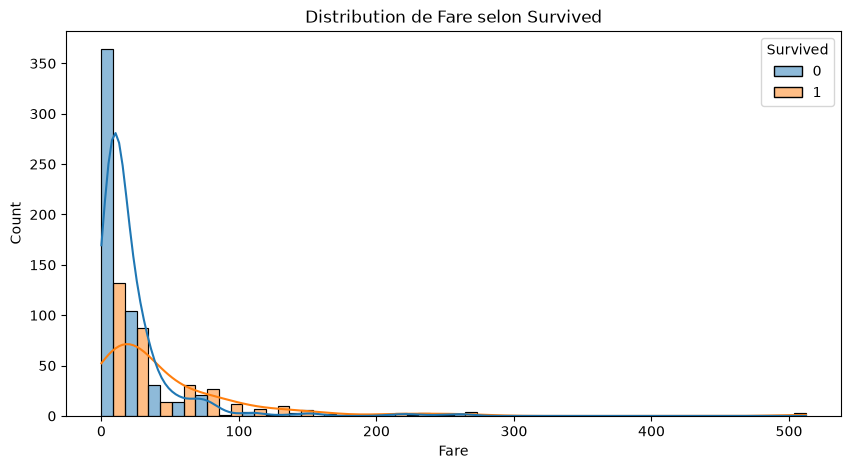

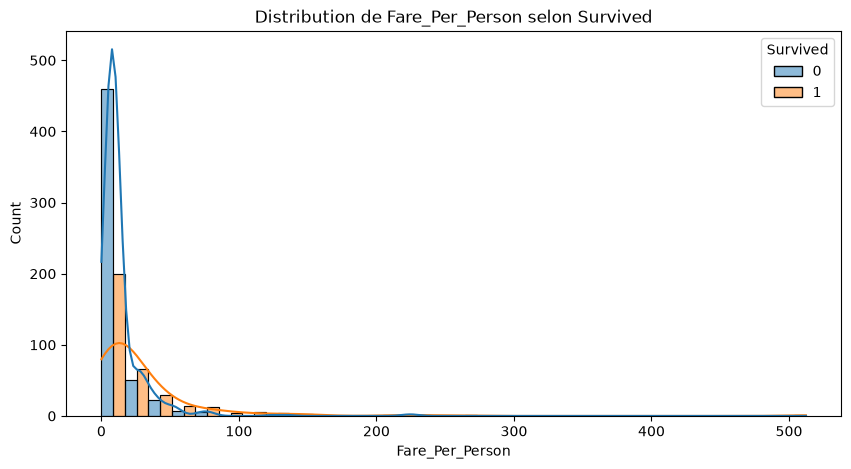

In [719]:
for col in X.select_dtypes(include="float"):

    plt.figure(figsize=(10, 5))

    sns.histplot(

        data=X,

        x=col,

        hue=y,

        bins=30,

        kde=True,

        multiple="dodge"
    )

    plt.title(f"Distribution de {col} selon Survived")


### Visualisation des variable categorielle

/tmp/ipykernel_578308/1310958322.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in X.select_dtypes(include=["object", "category"]).columns:


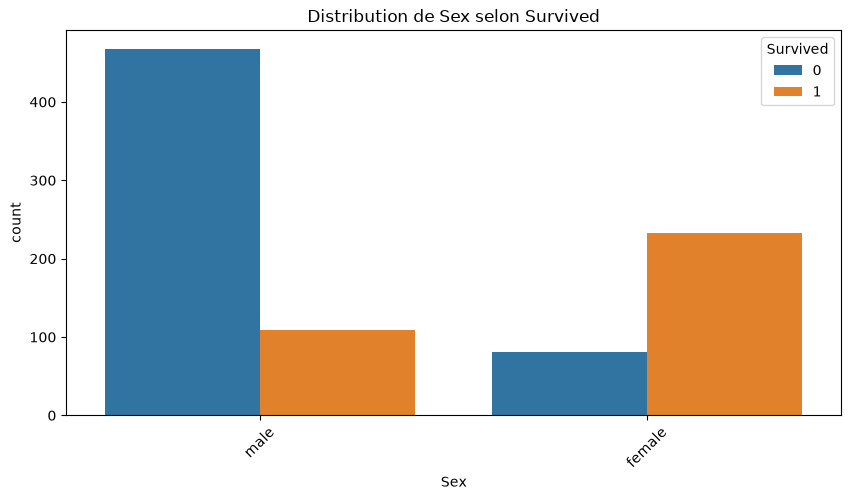

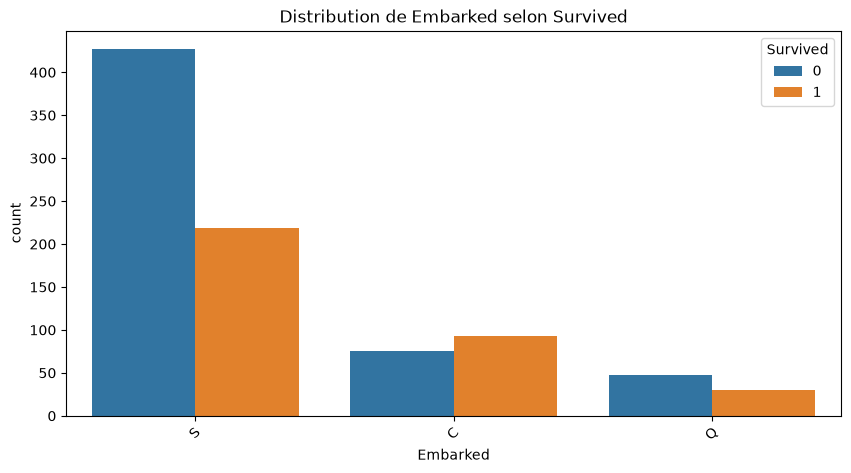

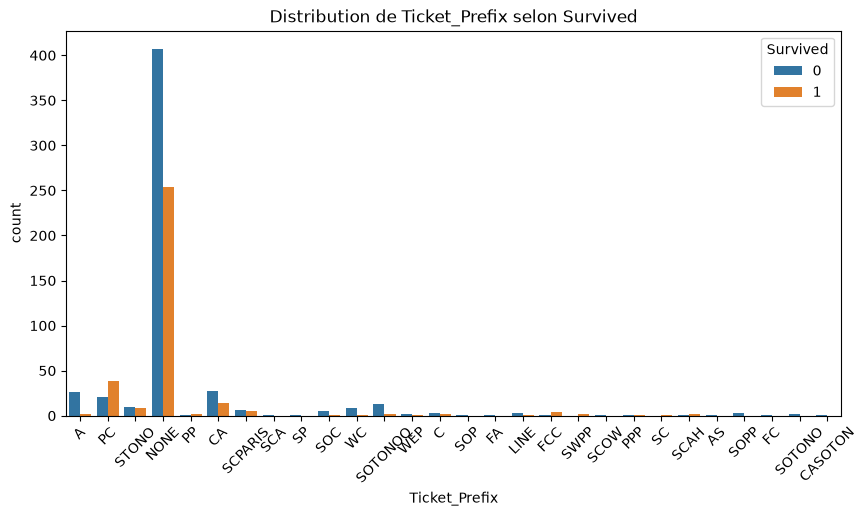

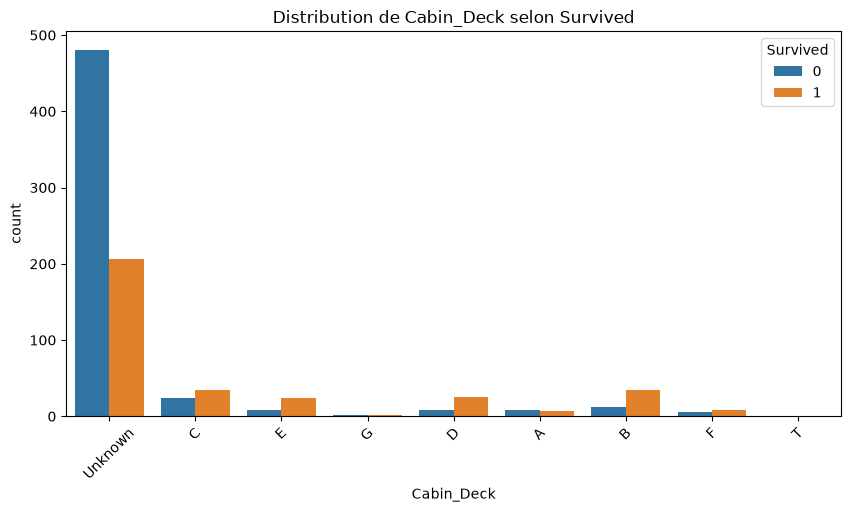

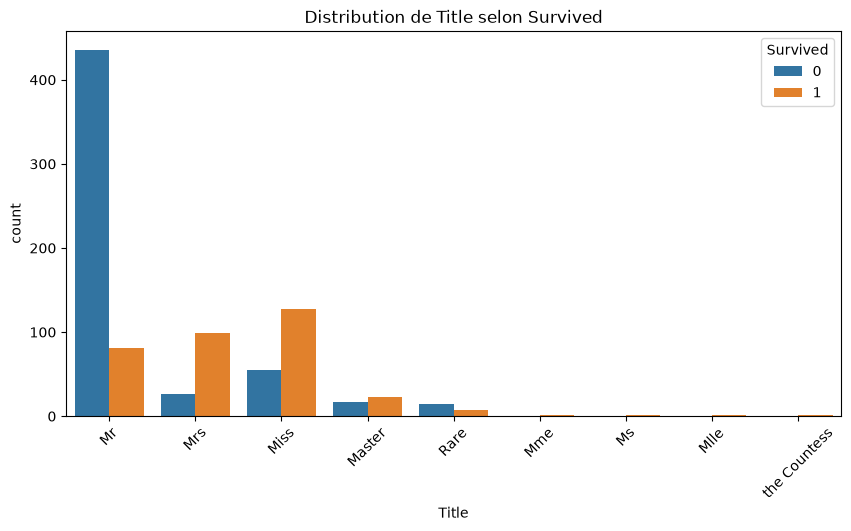

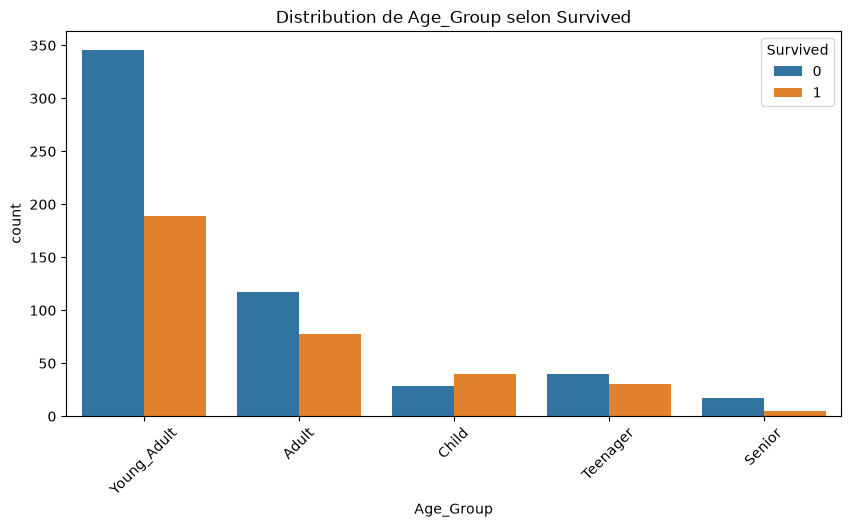

In [720]:
for col in X.select_dtypes(include=["object", "category"]).columns:

    plt.figure(figsize=(10, 5))

    sns.countplot(

        data=X,

        x=col,

        hue=y
    )

    plt.title(f"Distribution de {col} selon Survived")

    plt.xticks(rotation=45)
    
    plt.show()

### Separation du train et du test 

In [721]:
x_train , x_test , y_train , y_test = train_test_split(X , y , test_size=0.3)

### Creation des sous pipeline

In [722]:
X

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Ticket_Prefix,Ticket_Length,Cabin_Deck,Title,Family_Size,Is_Alone,Fare_Per_Person,Age_Group
0,3,male,22.0,1,0,7.2500,S,A,9,Unknown,Mr,2,0,3.62500,Young_Adult
1,1,female,38.0,1,0,71.2833,C,PC,8,C,Mrs,2,0,35.64165,Adult
2,3,female,26.0,0,0,7.9250,S,STONO,16,Unknown,Miss,1,1,7.92500,Young_Adult
3,1,female,35.0,1,0,53.1000,S,NONE,6,C,Mrs,2,0,26.55000,Young_Adult
4,3,male,35.0,0,0,8.0500,S,NONE,6,Unknown,Mr,1,1,8.05000,Young_Adult
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,2,male,27.0,0,0,13.0000,S,NONE,6,Unknown,Rare,1,1,13.00000,Young_Adult
887,1,female,19.0,0,0,30.0000,S,NONE,6,B,Miss,1,1,30.00000,Young_Adult
888,3,female,28.0,1,2,23.4500,S,WC,10,Unknown,Miss,4,0,5.86250,Young_Adult
889,1,male,26.0,0,0,30.0000,C,NONE,6,C,Mr,1,1,30.00000,Young_Adult


Pipiline des valeur numerique

In [723]:
num_col = ["Age","SibSp","Parch","Fare","Ticket_Length","Family_Size","Fare_Per_Person"]

cat_col = ["Embarked","Ticket_Prefix","Cabin_Deck","Title","Age_Group","Sex"]

ignore_col = ["Pclass","Is_Alone"]



num_pipeline = make_pipeline(

    StandardScaler()

)

cat_pipeline = make_pipeline(

    (OneHotEncoder(handle_unknown="ignore",sparse_output=False))

)

prepo = make_column_transformer(

    (num_pipeline , num_col),

    (cat_pipeline , cat_col),

    ("passthrough",ignore_col),

    verbose_feature_names_out=False,

).set_output(transform="pandas")


x_train  =  prepo.fit_transform(x_train)

x_test = prepo.transform(x_test)

df_test 

x_train

,Age,SibSp,Parch,Fare,Ticket_Length,Family_Size,Fare_Per_Person,Embarked_C,Embarked_Q,Embarked_S,...,Title_the Countess,Age_Group_Adult,Age_Group_Child,Age_Group_Senior,Age_Group_Teenager,Age_Group_Young_Adult,Sex_female,Sex_male,Pclass,Is_Alone
155,1.684686,-0.483934,0.800525,0.631645,0.461316,0.071369,0.310222,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1,0
21,0.353784,-0.483934,-0.465280,-0.381713,-0.273722,-0.563817,-0.193977,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,2,1
743,-0.429099,0.446593,-0.465280,-0.316780,-0.273722,0.071369,-0.335064,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,3,0
848,-0.115946,-0.483934,0.800525,0.037210,-0.273722,0.071369,-0.094218,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,2,0
641,-0.429099,-0.483934,-0.465280,0.797555,0.461316,-0.563817,1.410716,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40,0.823514,0.446593,-0.465280,-0.455548,-1.008760,0.071369,-0.429479,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,3,0
538,-0.115946,-0.483934,-0.465280,-0.350294,-0.273722,-0.563817,-0.151223,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,3,1
90,-0.037658,-0.483934,-0.465280,-0.485397,-0.273722,-0.563817,-0.335064,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,3,1
794,-0.350811,-0.483934,-0.465280,-0.488626,-0.273722,-0.563817,-0.339459,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,3,1


### Entrainement de quelque models 

In [724]:
models = {
    
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "KNN": KNeighborsClassifier(),

    "Random Forest": RandomForestClassifier(random_state=42),

    "SVC": SVC(probability=True),

    "Gradient Boosting": GradientBoostingClassifier(random_state=42),

    "Voting Estimator" : VotingClassifier(
        
         estimators=[
             
        ("logistic", LogisticRegression(max_iter=1000)),

        ("knn", KNeighborsClassifier()),

        ("random_forest", RandomForestClassifier(random_state=42)),

        ("svc", SVC(probability=True)),

        ("gradient_boosting", GradientBoostingClassifier(random_state=42))
    ],
    
    voting="soft",

    n_jobs=-1
    )
    

}
score = {}

cv = StratifiedKFold(

    n_splits=5,

    shuffle=True,

    random_state=42
)

for name, model in models.items():

    sc = cross_validate(

        model,

        x_train,

        y_train,

        cv=cv,

        scoring=["accuracy", "precision", "recall", "f1"],

        return_train_score=True
    )

    score[name] = {

        "Accuracy": sc["test_accuracy"].mean(),

        "Precision": sc["test_precision"].mean(),

        "Recall": sc["test_recall"].mean(),

        "F1": sc["test_f1"].mean(),

    }

score =  pd.DataFrame(score)

score

/home/billa/IA & ML/env/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/billa/IA & ML/env/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/billa/IA & ML/env/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/billa/IA & ML/env/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 a

,Logistic Regression,KNN,Random Forest,SVC,Gradient Boosting,Voting Estimator
Accuracy,0.802671,0.778503,0.786594,0.797845,0.817032,0.805832
Precision,0.756473,0.743105,0.749542,0.754149,0.790372,0.775887
Recall,0.729167,0.654167,0.679167,0.704167,0.720833,0.704167
F1,0.741221,0.695067,0.711221,0.727974,0.751316,0.736740


### Observation

Le model le plus performant est le "Gradient Boosting"

In [725]:
best_model = GradientBoostingClassifier(random_state=42)

best_model.fit(x_train,y_train)

best_model.score(x_train,y_train)

feature_names = prepo.get_feature_names_out()

importance = best_model.feature_importances_

feature_importance = pd.DataFrame({

    "Feature": feature_names,

    "Importance": importance

}).sort_values(

    by="Importance",

    ascending=False
)

feature_importance


,Feature,Importance
47,Title_Mr,0.298214
59,Pclass,0.130840
6,Fare_Per_Person,0.096740
0,Age,0.092608
57,Sex_female,0.073381
...,...,...
45,Title_Mlle,0.000000
51,Title_the Countess,0.000000
49,Title_Ms,0.000000
53,Age_Group_Child,0.000000


### Selection des feature avec plus de 0.5% d'importance

In [726]:
sort_feature = feature_importance[feature_importance["Importance"]>0.005]

best_feature = sort_feature['Feature'].tolist()

X_train_selected = x_train[best_feature]

X_test_selected = x_test[best_feature]



### Re-entrainement du model

In [727]:
best_model.fit(X_train_selected , y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

### Test sur les données d'entrainement

In [728]:
best_model.score(X_train_selected,y_train)

0.9181380417335474

### Test du les données de test

In [729]:
best_model.score(X_test_selected,y_test)

0.8470149253731343

### Recherche des meilleur parametre

In [730]:
param_grid = {
    "n_estimators": [100, 200, 300, 500],

    "learning_rate": [0.01, 0.03, 0.05, 0.1],

    "max_depth": [1, 2, 3],

    "min_samples_split": [10, 20, 30],

    "min_samples_leaf": [5, 10, 15, 20],

    "subsample": [0.6, 0.75, 0.9, 1.0],

    "max_features": [None, "sqrt", "log2", 0.8]
}

checher =  RandomizedSearchCV(

        estimator = best_model ,

        param_distributions = param_grid ,

        cv = cv ,

        scoring="accuracy",

        n_iter=100,

        verbose=1,

        random_state=42,

)

checher.fit(X_train_selected,y_train)

checher.best_params_

Fitting 5 folds for each of 100 candidates, totalling 500 fits


{'subsample': 0.9,
 'n_estimators': 300,
 'min_samples_split': 30,
 'min_samples_leaf': 20,
 'max_features': None,
 'max_depth': 3,
 'learning_rate': 0.05}

In [731]:
best_param =  checher.best_params_


### Ré-entrainement du model avec les nouveau parametre

In [732]:
best_model =  GradientBoostingClassifier(**best_param,random_state=42)

best_model.fit(X_train_selected , y_train)


,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.05
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",300
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",0.9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",30
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * 

### Test sur les données d'entrainement 

In [733]:
best_model.score(X_train_selected,y_train)

0.9036918138041734

### Test sur les données de test 

In [734]:
best_model.score(X_test_selected,y_test)

0.8432835820895522

### Visualisation de la coube d'aprentissage

In [735]:
n , train_score , val_score =  learning_curve(best_model , X_train_selected , y_train , train_sizes=np.linspace(0.1,1,20),cv=cv)

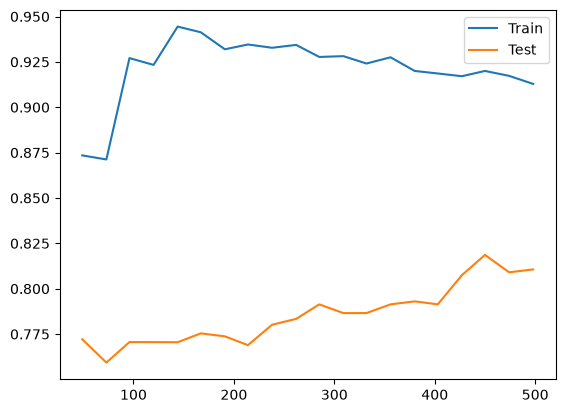

In [736]:
fig , ax = plt.subplots()

ax.plot(n,train_score.mean(axis=1),label="Train")

ax.plot(n,val_score.mean(axis=1),label="Test")

ax.legend()

### Metric du model

In [741]:
pred =  best_model.predict(X_test_selected)

accuracy_score(pred,y_test)


0.8432835820895522

### Exportation du csv

In [ ]:
df_test = feature_engineering(df_test) 

df_test["Age"] = num_imputer.fit_transform(df_test[["Age"]])

df_test["Embarked"] = cat_imputer.fit_transform(df_test[["Embarked"]]).ravel()

df_test["Age_Group"] = cat_imputer.fit_transform(df_test[["Age_Group"]]).ravel()

df_test =  prepo.fit_transform(df_test)



In [743]:
df_test

,Age,SibSp,Parch,Fare,Ticket_Length,Family_Size,Fare_Per_Person,Embarked_C,Embarked_Q,Embarked_S,...,Title_Rare,Age_Group_Adult,Age_Group_Child,Age_Group_Senior,Age_Group_Teenager,Age_Group_Young_Adult,Sex_female,Sex_male,Pclass,Is_Alone
0,0.386231,-0.499470,-0.400248,-0.497811,-0.310710,-0.553443,-0.392588,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,3,1
1,1.371370,0.616992,-0.400248,-0.512660,-0.310710,0.105643,-0.514205,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,3,0
2,2.553537,-0.499470,-0.400248,-0.464532,-0.310710,-0.553443,-0.340384,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,2,1
3,-0.204852,-0.499470,-0.400248,-0.482888,-0.310710,-0.553443,-0.369179,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,3,1
4,-0.598908,0.616992,0.619896,-0.417971,0.044145,0.764728,-0.497467,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
413,-0.204852,-0.499470,-0.400248,-0.493856,0.753853,-0.553443,-0.386385,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,3,1
414,0.740881,-0.499470,-0.400248,1.312180,0.398999,-0.553443,2.446718,1.0,0.0,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1,1
415,0.701476,-0.499470,-0.400248,-0.508183,3.947539,-0.553443,-0.408859,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,3,1
416,-0.204852,-0.499470,-0.400248,-0.493856,-0.310710,-0.553443,-0.386385,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,3,1


In [763]:
X_df_test_selected = df_test.reindex(
    columns=X_train_selected.columns,
    fill_value=0
)

X_df_test_selected["Fare"] = X_df_test_selected["Fare"].fillna(
    X_train_selected["Fare"].median()
)

X_df_test_selected["Fare_Per_Person"] = X_df_test_selected["Fare_Per_Person"].fillna(
    X_train_selected["Fare_Per_Person"].median()
)

X_df_test_selected.isna().sum()

Title_Mr               0
Pclass                 0
Fare_Per_Person        0
Age                    0
Sex_female             0
Family_Size            0
Fare                   0
Title_Rare             0
Cabin_Deck_Unknown     0
Ticket_Prefix_SWPP     0
Ticket_Length          0
Cabin_Deck_E           0
Cabin_Deck_C           0
Cabin_Deck_D           0
Embarked_S             0
Title_Mrs              0
Ticket_Prefix_STONO    0
Ticket_Prefix_SOPP     0
SibSp                  0
Sex_male               0
dtype: int64

In [765]:
pred = best_model.predict(X_df_test_selected)



In [768]:
df_t  =  pd.read_csv("dataset/1/test.csv")

df_t =  df_t["PassengerId"].to_numpy()


df_t =  pd.DataFrame({
    "PassengerId" : df_t,
    "Survived" : pred
})

In [770]:
df_t.to_csv("dataset/1/gender_submission.csv",index=False)